### Import modules

In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from ensemble_outlier_sample_detection import EnsembleOutlierSampleDetector
import matplotlib.pyplot as plt
import seaborn as sns

### Define some constants

In [2]:
SEED = 334
n_splits = 5
kf = KFold(n_splits = n_splits, shuffle =True, random_state = SEED)

### Load dataset
Use a dataset where some of the `y` values are strange.  

Original data: https://github.com/hkaneko1985/ensemble_outlier_sample_detection  
(Used under the MIT License)

In [3]:
example_path = 'example_chache.csv'
df = pd.read_csv(example_path, index_col = 0, comment='#')
X = df.iloc[:, 1:]
y = df.iloc[:, 0]
display(X.head(), y.head())

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10
sample_1,-0.008829,0.020603,0.012806,0.022196,0.014404,0.000542,-0.017258,0.035589,0.002711,-0.005959
sample_2,0.054267,-0.011827,0.024182,0.010591,0.043688,0.028225,-0.026693,0.002172,0.036835,-0.030305
sample_3,0.007996,0.085998,0.083851,0.068907,0.046763,0.029664,0.023624,0.026716,0.005059,0.018760
sample_4,0.007808,0.058072,0.071922,0.075210,0.070864,0.041052,0.031952,0.061823,0.032988,-0.028616
sample_5,0.025469,0.069069,0.039437,0.035413,0.026697,0.018137,0.024466,0.064571,0.043171,0.033427


sample_1    4.862230
sample_2    4.979903
sample_3    5.068076
sample_4    5.166788
sample_5    5.374128
Name: y, dtype: float64

### Use `pairplot` to visually check the distribution
Correlation between `y` and other variables shows that there is a deviant population.

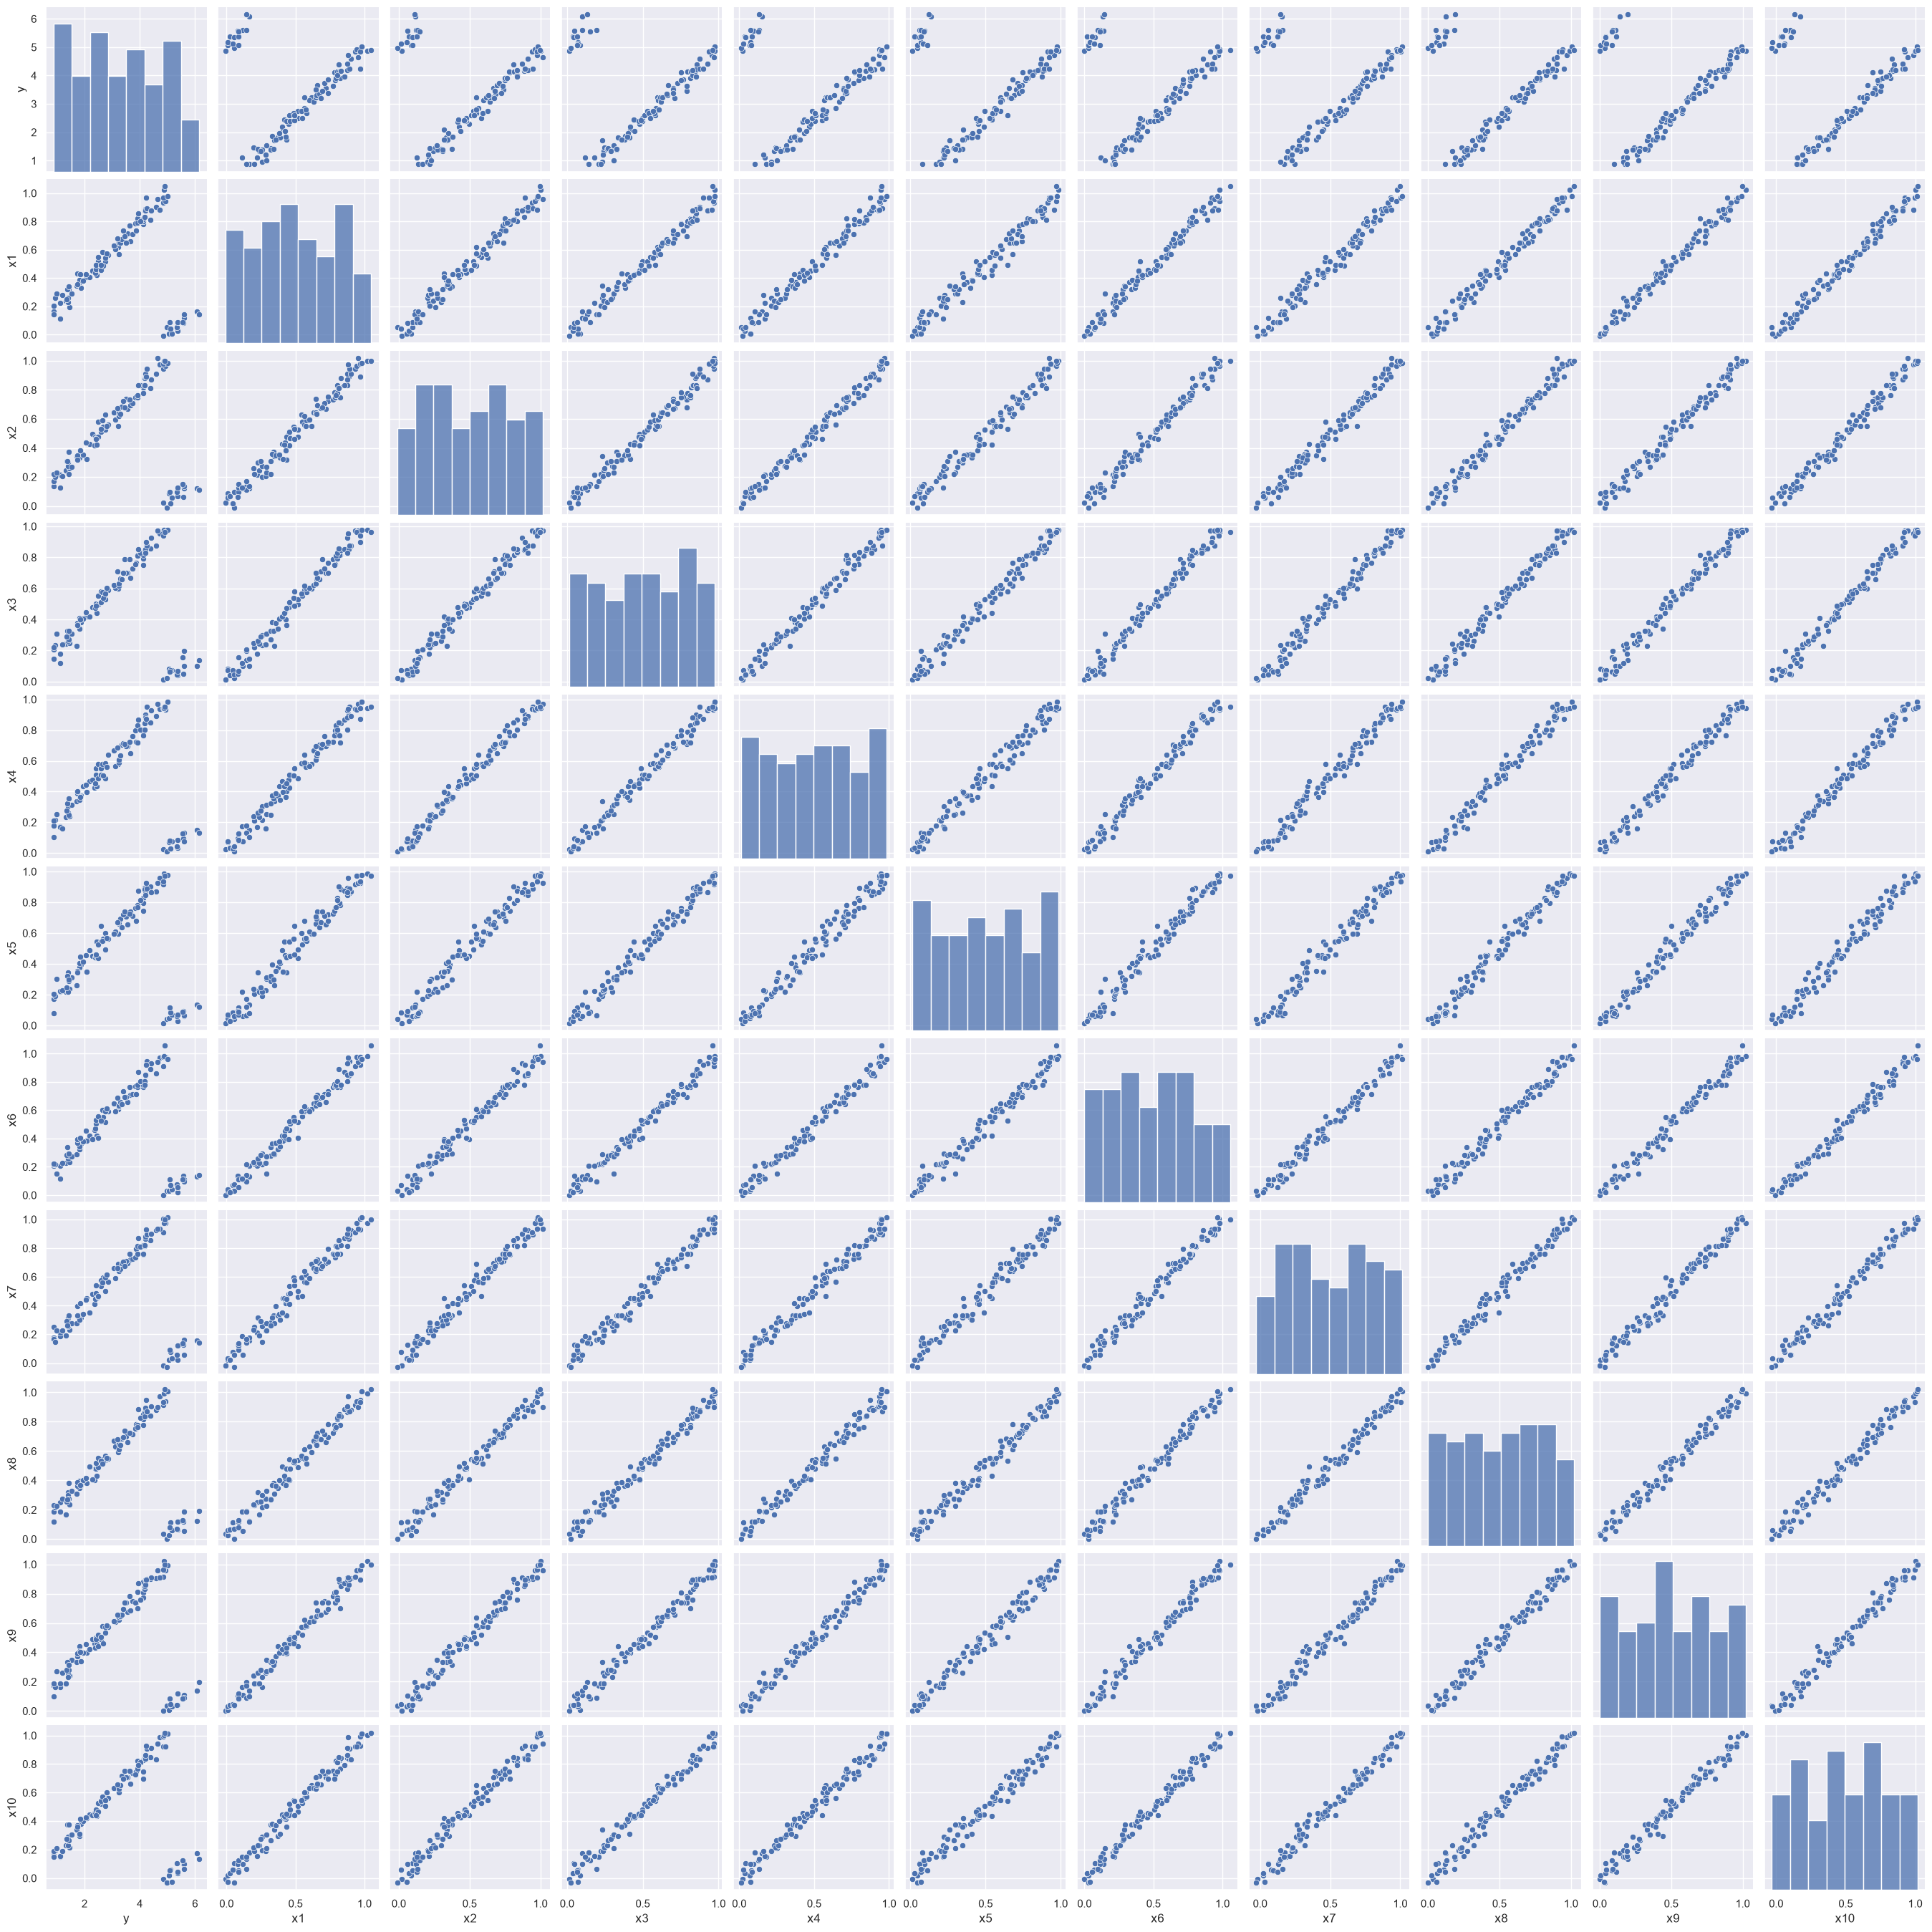

In [4]:
sns.set_theme(style = 'darkgrid')
sns.pairplot(data = df)

### Define RandomForest estimator

In [5]:
rf = RandomForestRegressor(n_jobs = -1, random_state = SEED)

### Not ELO
#### Prediction
Cross Validation

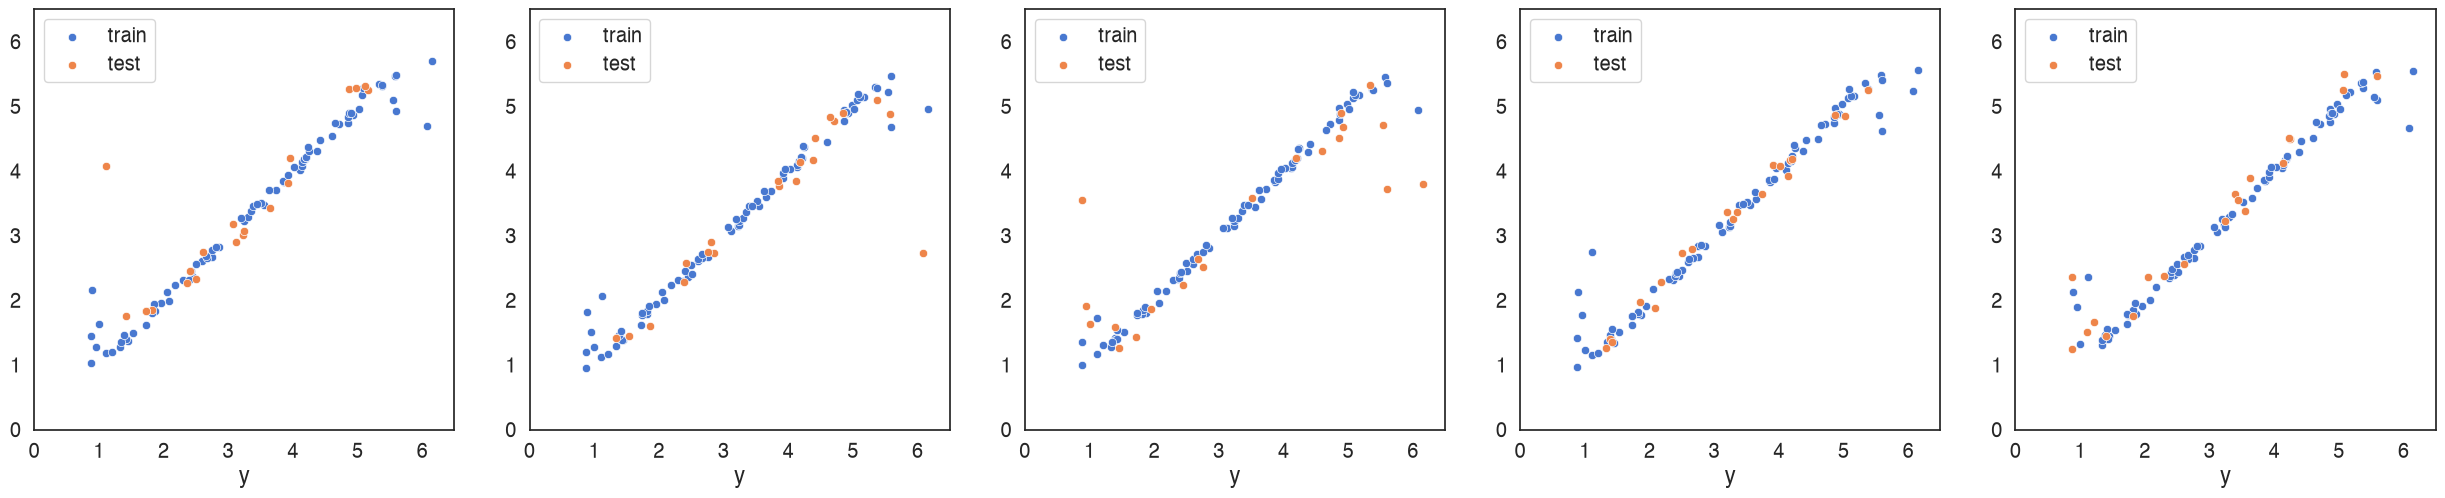

In [6]:
score_names = ['RMSE', 'MAE', 'R2']
data_names = ['train', 'test']
metrics = dict(zip(score_names, [root_mean_squared_error, mean_absolute_error, r2_score]))
scores = {data_name: {score_name: [] for score_name in score_names} for data_name in data_names}

sns.set_theme(style = 'white', palette = 'muted', font = 'Helvetica', font_scale = 1.3)
fig = plt.figure(facecolor = 'white', figsize = (5*n_splits, 5))
for j, (i_train, i_test) in enumerate(kf.split(X, y)):
    ax = fig.add_subplot(1, n_splits, j+1)

    X_train, X_test, y_train, y_test = X.iloc[i_train], X.iloc[i_test], y.iloc[i_train], y.iloc[i_test]

    rf.fit(X_train, y_train)

    y_pred_on_train = rf.predict(X_train)
    y_pred_on_test = rf.predict(X_test)

    sns.scatterplot(x=y_train, y=y_pred_on_train, ax = ax, label = 'train')
    sns.scatterplot(x=y_test, y=y_pred_on_test, ax = ax, label = 'test')

    ax.set_xlim(0, 6.5)
    ax.set_ylim(0, 6.5)

    ax.set_aspect('equal')

    for score_name, metric in metrics.items():
        scores['train'][score_name].append(metric(y_train, y_pred_on_train))
        scores['test'][score_name].append(metric(y_test, y_pred_on_test))
fig.tight_layout()

### Scores

In [7]:
for data_name in data_names:
    for score_name in score_names:
        print('{1}({0}):\t{2:.3f}'.format(data_name, score_name, np.average(scores[data_name][score_name])))

RMSE(train):	0.259
MAE(train):	0.118
R2(train):	0.967
RMSE(test):	0.594
MAE(test):	0.315
R2(test):	0.792


### ELO
`fit` returns the detector itself. `outlier_support_` and `inlier_support_` are boolean masks of the samples, and `n_iter_` is the number of iterations that `fit` ran.

In [8]:
elo = EnsembleOutlierSampleDetector(random_state = SEED, n_jobs = -1, cv = 5, metric = 'rmse').fit(X, y)
print('{} outliers detected in {} iterations:'.format(elo.outlier_support_.sum(), elo.n_iter_))
print(y.index[elo.outlier_support_].tolist())

  0%|          | 0/3000 [00:00<?, ?it/s]

15 outliers detected in 3 iterations:
['sample_1', 'sample_2', 'sample_3', 'sample_4', 'sample_5', 'sample_6', 'sample_7', 'sample_8', 'sample_9', 'sample_10', 'sample_11', 'sample_12', 'sample_13', 'sample_14', 'sample_15']


#### Extract

In [9]:
flags = elo.inlier_support_
X_normal = X.loc[flags]
y_normal = y[flags]

#### pairplot
You will see that the outlier samples have been removed.

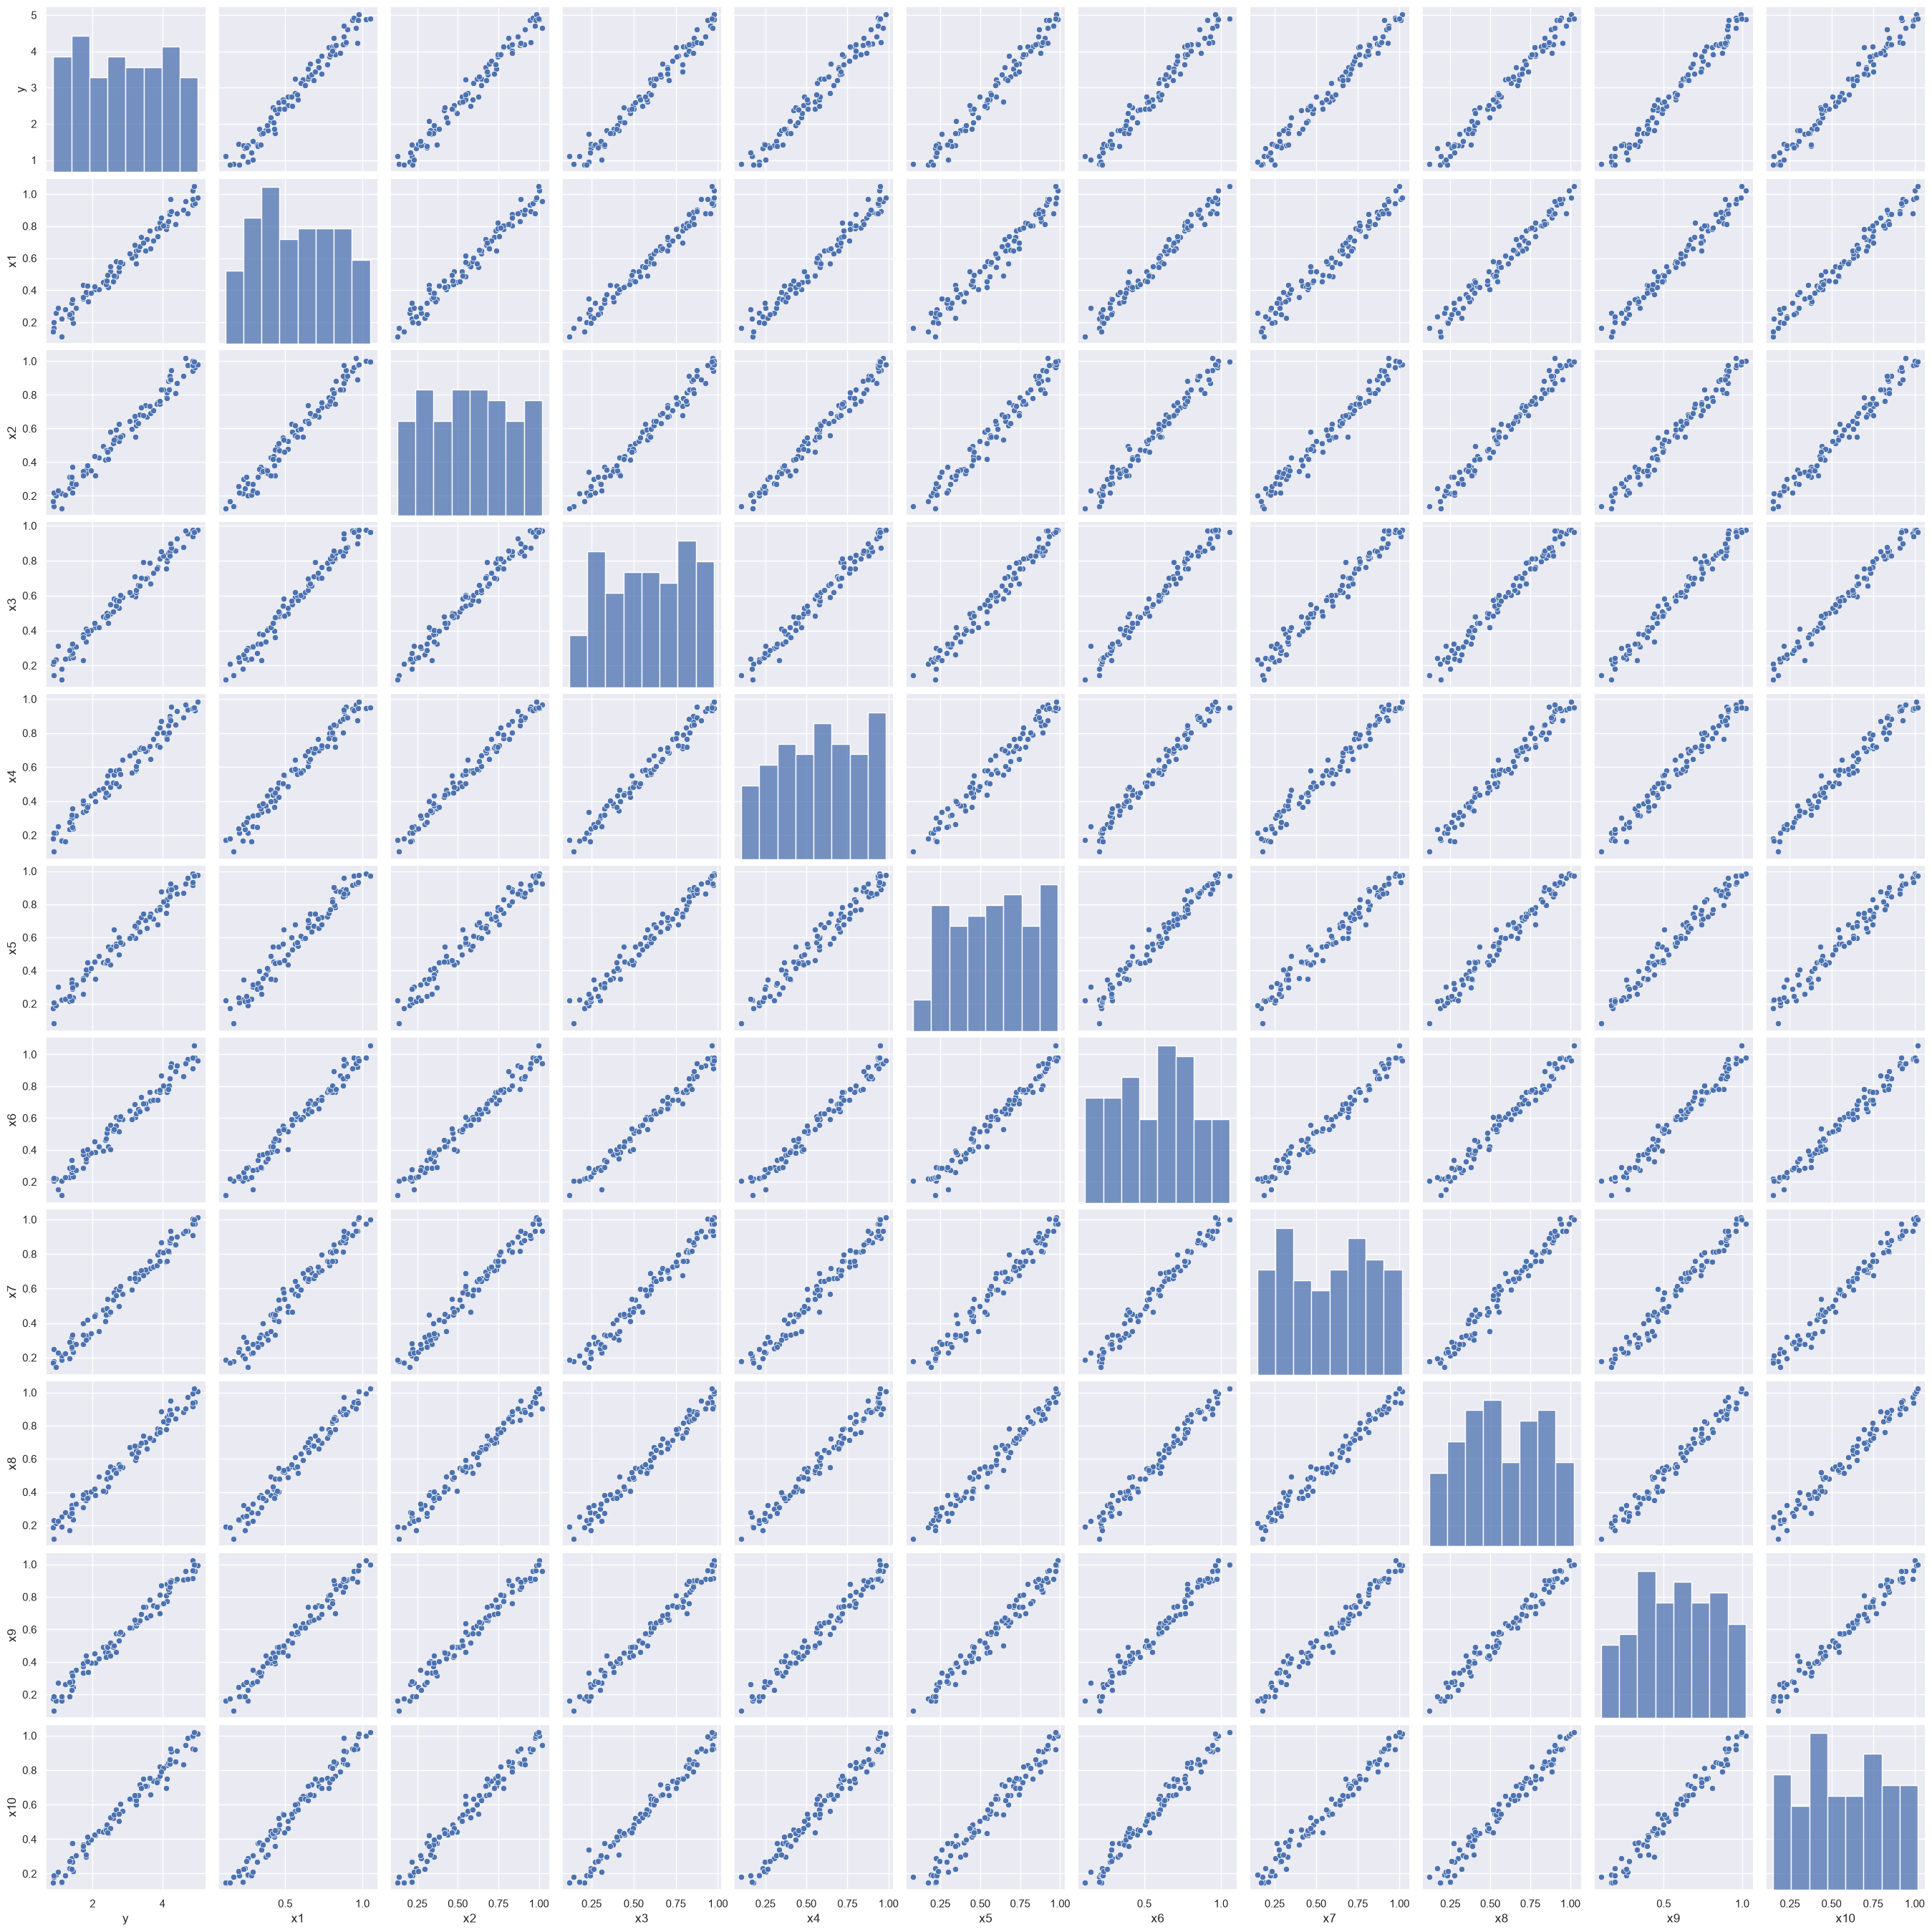

In [10]:
sns.set_theme(style = 'darkgrid')
sns.pairplot(data = pd.concat([y_normal, X_normal], axis = 1))

#### Predict

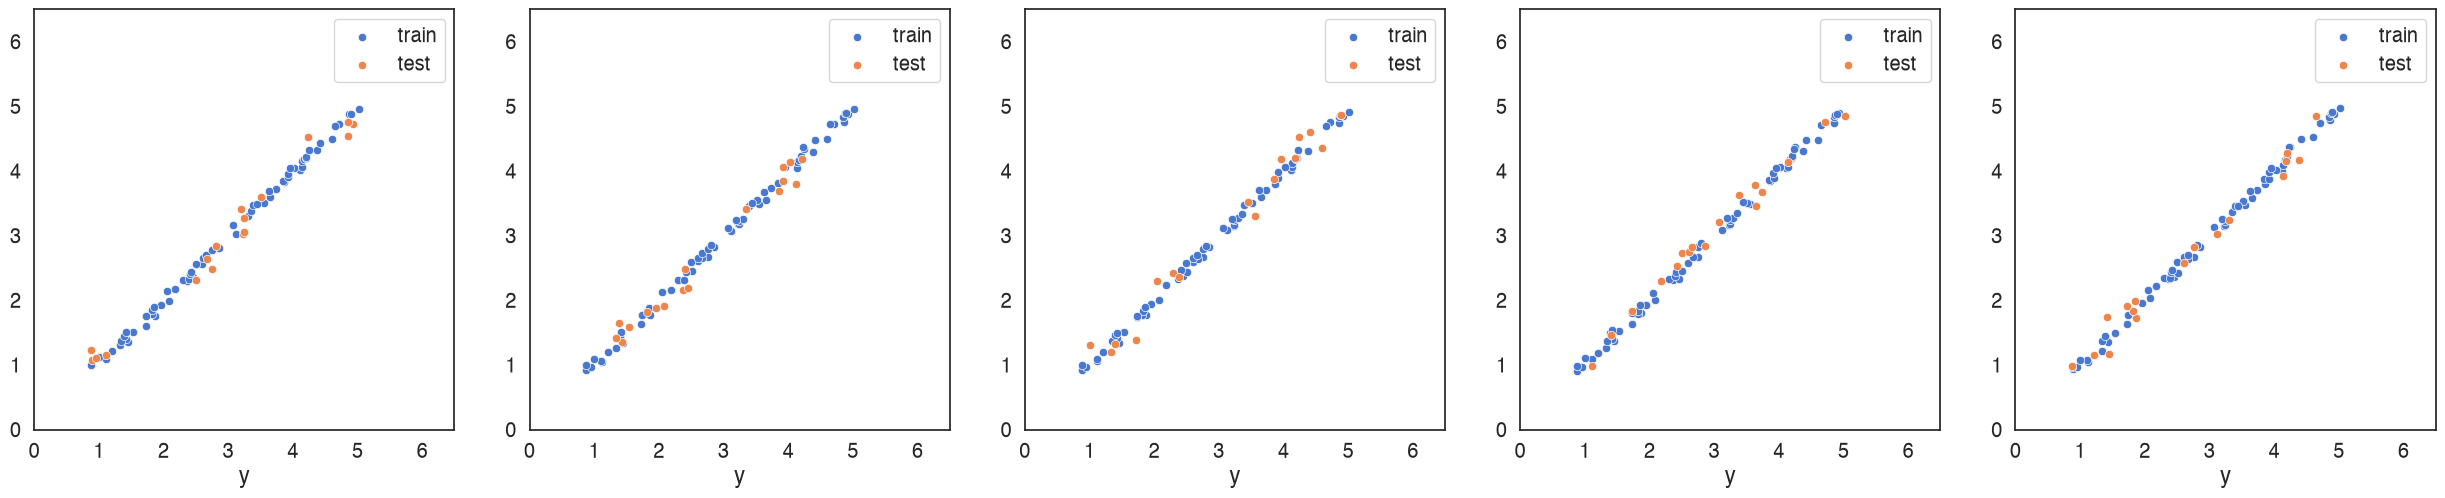

In [11]:
score_names = ['RMSE', 'MAE', 'R2']
data_names = ['train', 'test']
metrics = dict(zip(score_names, [root_mean_squared_error, mean_absolute_error, r2_score]))
scores = {data_name: {score_name: [] for score_name in score_names} for data_name in data_names}

sns.set_theme(style = 'white', palette = 'muted', font = 'Helvetica', font_scale = 1.3)
fig = plt.figure(facecolor = 'white', figsize = (5*n_splits, 5))
for j, (i_train, i_test) in enumerate(kf.split(X_normal, y_normal)):
    ax = fig.add_subplot(1, n_splits, j+1)

    X_train, X_test, y_train, y_test = X_normal.iloc[i_train], X_normal.iloc[i_test], y_normal.iloc[i_train], y_normal.iloc[i_test]

    rf.fit(X_train, y_train)

    y_pred_on_train = rf.predict(X_train)
    y_pred_on_test = rf.predict(X_test)

    sns.scatterplot(x=y_train, y=y_pred_on_train, ax = ax, label = 'train')
    sns.scatterplot(x=y_test, y=y_pred_on_test, ax = ax, label = 'test')

    ax.set_xlim(0, 6.5)
    ax.set_ylim(0, 6.5)

    ax.set_aspect('equal')

    for score_name, metric in metrics.items():
        scores['train'][score_name].append(metric(y_train, y_pred_on_train))
        scores['test'][score_name].append(metric(y_test, y_pred_on_test))
fig.tight_layout()

#### Scores

In [12]:
for data_name in data_names:
    for score_name in score_names:
        print('{1}({0}):\t{2:.3f}'.format(data_name, score_name, np.average(scores[data_name][score_name])))

RMSE(train):	0.060
MAE(train):	0.050
R2(train):	0.998
RMSE(test):	0.167
MAE(test):	0.141
R2(test):	0.980
